## I3读者模式：新算的构造订单示例与已接受摘要回放

本Notebook中新计算的数值都是**构造方法示例**，不是市场观测或历史验证。固定父单、部分成交和零成交示例会在运行相应单元时新算；walk-forward、敏感度、消融和账本审计部分展示已接受的2026-10-14当前信号摘要。更早的A7-B R2R6记录属于另一证据身份。French原始、提取和处理后数据未随包提供。French路径的A10-A有限范围设计已接受，但执行仍受阻；A10-A.1协议已完成技术接受，仍待数据权利和执行授权。G01的权利、主体与用途尚不明确；G05/A10-B未获授权。

原课程正文介绍更完整的方法。本读者Notebook以下代码与标签界定本Notebook实际执行和展示的内容；完整研究仍受上述数据权利和执行授权限制。


# 项目4成本与执行实验：互动教学Notebook

**模块**：项目4多因子策略执行实验  
**接口约定**：`qa/a7/ch35_ch36_batch/INTERFACE_CONTRACT.md`  
**数据状态**：构造教学数据（随机种子`20261210`；非实证数据）

本Notebook介绍构造的执行成本方法。它会新算两个小例子：固定父单的算法比较，以及流动性上限下的部分成交/零成交。其余章节展示已接受的当前信号摘要，不会重新运行完整策略。

1. 比较**TWAP**、**预测VWAP**和**滞后观测POV**切片。
2. 记录**部分成交**、截止时剩余量（$Q = F + R$）和零成交边界。
3. 通过直接恒等式和四项分解对照**实施短缺（Implementation Shortfall，IS）**。
4. 阅读已记录的**现金、持仓、净值、利息和借券费**审计。在成本消费者中，每个事件先结算此前余额和可用估值，再处理新观测到的成交或估值；应计现金利息按事件入账。
5. 解读已记录的**60个月训练 / 36个月测试**walk-forward摘要。本Notebook只展示保存的摘要，不运行该walk-forward。
6. 比较指定构造成本情景下已记录的毛收益和净收益。


In [ ]:
from pathlib import Path
import os, sys, uuid
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "pyproject.toml").is_file() and (p / "src/quant_course").is_dir())
for path in (ROOT / "src", ROOT / "code", ROOT):
    if str(path) not in sys.path: sys.path.insert(0, str(path))
os.environ["MPLBACKEND"] = "Agg"
os.chdir(ROOT)
RUN_DIR = ROOT / "runs" / ("cost_execution_lab_" + uuid.uuid4().hex)
RUN_DIR.mkdir(parents=True, exist_ok=False)
print("Run directory:", RUN_DIR.relative_to(ROOT))
import json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from quant_course.execution_costs import ExecutionConfig
from projects.project04.cost_execution_lab.p4_cost_bridge import estimate_frozen_volume_profile, run_fixed_parent_comparison, run_partial_and_zero_fill_demo
print("Small CONSTRUCTED execution examples + accepted 2026-10-14 current-signal summary replay; full P4 strategy SKIPPED")


## 第1步：配置与冻结的日内成交量曲线

Notebook读取声明的成本配置，并按指定的数据生成过程（DGP）用60条合成训练样本估计一条U形曲线。这些样本是构造数据，不是交易所实测成交量。曲线在使用前冻结。

13个半小时槽的起点为UTC 09:30、10:00、……、15:30。图中刻度标示槽起点；成交发生在每个起点后15分钟，terminal估值时点为UTC 16:00:30。本构造在每月第三个自然日再平衡，不使用真实交易所日历。


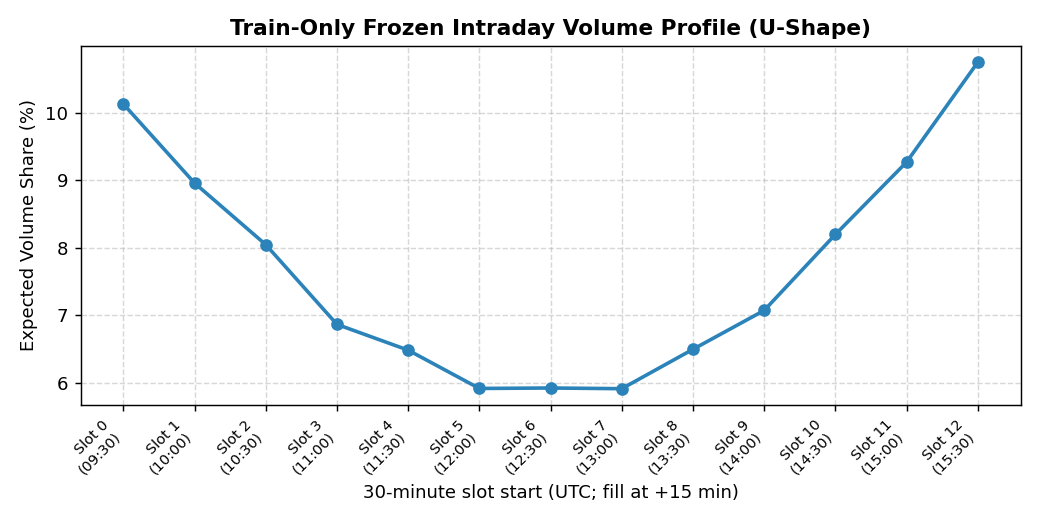

In [ ]:
CONFIG_PATH = ROOT / "projects/project04/cost_execution_lab/config.json"
with CONFIG_PATH.open(encoding="utf-8") as stream:
    config_data = json.load(stream)
authoritative = json.loads((ROOT / "fixtures/projects/project04/summary_results_current_signal_20261014.json").read_text(encoding="utf-8"))
SEED = config_data["universe"]["seed"]
frozen_profile = estimate_frozen_volume_profile(
    n_slots=config_data["intraday_bridge"]["slots_per_day"], seed=SEED
)

plt.figure(figsize=(8, 4))
slots_x = [f"Slot {i}\n({(9 * 60 + 30 + 30 * i) // 60:02d}:{(9 * 60 + 30 + 30 * i) % 60:02d})" for i in range(13)]
plt.plot(range(13), frozen_profile * 100, marker='o', color='#2b83ba', linewidth=2)
plt.title("Train-Only Frozen Intraday Volume Profile (U-Shape)", fontweight="bold")
plt.xlabel("30-minute slot start (UTC; fill at +15 min)")
plt.ylabel("Expected Volume Share (%)")
plt.xticks(range(13), slots_x, rotation=45, ha='right', fontsize=8)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(RUN_DIR / "constructed_volume_profile.png", dpi=130)
plt.show()

print(f"Volume profile sums to: {frozen_profile.sum():.6f}")


## 第2步：固定父单切片比较（TWAP、VWAP与POV）

新算示例将相同的10,000股买入和卖出父单放到同一条构造日内路径及13个时槽中执行。下表只展示**买入**结果。它检查$Q = F + R$、成交均价，以及实施短缺直接恒等式与四项分解是否一致。


In [ ]:
cost_cfg = config_data["execution_cost_model"]
cfg = ExecutionConfig(
    commission_rate=cost_cfg["commission_rate"],
    commission_per_share=cost_cfg["commission_per_share"],
    half_spread_bps=cost_cfg["half_spread_bps"],
    temp_impact_coef=cost_cfg["temp_impact_coef"],
    temp_impact_exp=cost_cfg["temp_impact_exp"],
    perm_impact_coef=cost_cfg["perm_impact_coef"],
    max_participation=cost_cfg["max_participation"],
    cash_rate_annual=cost_cfg["cash_rate_annual"],
    cash_debit_rate_annual=cost_cfg["cash_debit_rate_annual"],
    borrow_rate_annual=cost_cfg["borrow_rate_annual"],
    day_count_basis=cost_cfg["day_count_basis"],
)

fixed_res = run_fixed_parent_comparison(cfg, frozen_profile, seed=SEED)
for side, algorithms in fixed_res.items():
    for algorithm, row in algorithms.items():
        expected = authoritative["experiment_1_fixed_parent_comparison"][side][algorithm]
        for metric in ("total_is", "total_is_bps"):
            assert np.isclose(row[metric], expected[metric], rtol=1e-10, atol=1e-10)
        assert row["identity_verified"] == expected["identity_verified"]
buy_comp = fixed_res["BUY"]

df_comp = pd.DataFrame(buy_comp).T[[
    "parent_quantity", "filled_quantity", "fill_rate", "fill_vwap",
    "delay_cost", "realized_execution_cost", "explicit_fees", "total_is", "total_is_bps", "identity_verified"
]]
display(df_comp)


## 第3步：部分成交、截止剩余量与零成交处理

在低流动性构造路径中，参与率上限会限制子单规模。截止时未成交的股份构成剩余量$R = Q - F$。

参与率为0%时：
- 成交股数$F = 0$
- **成交均价为`None`**，因为没有股份成交
- 显性佣金为**0.00美元**
- 对本买入单，未成交机会成本为$Q \cdot (P_{terminal} - P_{arrival})$

示例使用100的到达价格和102.5的terminal估值。它只是买单未成交机会成本的构造说明，不是实证估计。


In [ ]:
stress_res = run_partial_and_zero_fill_demo(frozen_profile, seed=SEED)
for row, expected in zip(stress_res, authoritative["experiment_2_liquidity_stress"]):
    for metric in ("filled_quantity", "remainder_quantity", "realized_execution_cost", "unfilled_opportunity_cost", "explicit_fees", "total_is"):
        assert np.isclose(row[metric], expected[metric], rtol=1e-10, atol=1e-10)
    if row["fill_vwap"] is None or expected["fill_vwap"] is None:
        assert row["fill_vwap"] is expected["fill_vwap"]
    else:
        assert np.isclose(row["fill_vwap"], expected["fill_vwap"], rtol=1e-10, atol=1e-10)
df_stress = pd.DataFrame(stress_res)
display(df_stress[[
    "max_participation", "parent_quantity", "filled_quantity", "remainder_quantity",
    "fill_fraction", "fill_vwap", "realized_execution_cost", "unfilled_opportunity_cost", "total_is", "identity_verified"
]])


## 第4步：按时间顺序的walk-forward多因子回测（已接受摘要回放）

底层成本研究以60个月训练期和36个月测试期比较毛收益和净收益。其配置从2013-12开始输入97个月；首月为warm-up，随后有2014-01至2021-12共96个收益月。信号Notebook使用另一段从2014-01开始的96个月输入期。虽然随机种子相同，这两个构造也不因此逐元素相同。

本单元只读取已接受的2026-10-14当前信号摘要中的`experiment_3_walk_forward_performance`并展示结果，不重建目标权重，也不运行walk-forward。底层消费者的月度NAV收益覆盖上月末至本月末，首期以初始NAV为起点，包含本月执行前的融资计提以及执行后的估值变化；再平衡规模以融资计提后的调仓净值为基数。换手只计入已成交的风险资产名义金额，不把现金权重变化当成股票成交；年化换手为月均换手乘以12。这里展示的仍是构造摘要证据，不是现实市场验证。


In [ ]:
perf_dict = authoritative["experiment_3_walk_forward_performance"]
rows = [{"strategy": strategy, "window": window, **values} for strategy, windows in perf_dict.items() for window, values in windows.items()]
display(pd.DataFrame(rows))
print("Historical accepted CONSTRUCTED summary replay; no walk-forward run or new market verification")


## 第5步：高摩擦构造情景（已接受摘要回放）

本情景按指定的合成成本比较毛收益与净收益，只说明一条构造模型路径，不能证明真实市场alpha扣费后是否存在。下一单元展示保存摘要中的`experiment_4_zero_negative_result`，不会重新运行该情景。毛收益以及所有零值和负结果都应一并保留。


In [ ]:
display(pd.Series(authoritative["experiment_4_zero_negative_result"]))
print("Accepted historical negative/zero-result scenarios retained; no rerun")


## 第6步：成本、成交上限与目标规模敏感度（已接受摘要回放）

低参与率上限被设定为会约束这条构造成交量路径。目标规模扫描同时改变请求换手和gross敞口，因此是敞口与换手的联合情景，不是单独的换手效应。下一单元展示保存的敏感度摘要，不重新运行扫描。


In [ ]:
sens_res = authoritative["experiment_5_sensitivity_analysis"]
display(pd.DataFrame(sens_res["fee_and_participation"]))
display(pd.DataFrame(sens_res["target_weight_scale"]))


## 第7步：逐项摩擦消融（已接受摘要回放）

已记录的消融逐项加入摩擦层，并比较累计结果：
1. 无摩擦毛收益
2. 加入买卖价差半边
3. 加入临时市场冲击
4. 加入经纪佣金
5. 加入卖空借券费与现金融资

下方表格和图表回放保存的`experiment_6_ablation_study`摘要。它们不生成新一轮消融；负结果须与毛收益一同保留。


In [ ]:
df_abl = pd.DataFrame(authoritative["experiment_6_ablation_study"])
display(df_abl)
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(df_abl["stage"].str.replace("_"," "), df_abl["cagr"]*100)
ax.set(title="Historical accepted CONSTRUCTED ablation summary",ylabel="CAGR (%)")
ax.tick_params(axis="x",rotation=20); fig.tight_layout()
fig.savefig(RUN_DIR / "historical_constructed_ablation.png",dpi=130); plt.show()


## 第8步：多期资产负债表与现金账本审计（已接受摘要回放）

按此处的现金流符号约定，审计恒等式为：
$$\text{期末现金} = \text{期初现金} - \sum \text{带符号成交额} - \sum \text{费用} + \text{利息} - \text{借券费}$$

下一单元显示已接受摘要中的`ledger_audits`。它不重建账本，也不验证一次新运行。底层成本消费者中，每个事件会先结算应计利息和借券费用，并更新当时可用的估值，再登记后续成交或估值；这里显示的残差属于已保存的审计结果。


In [ ]:
display(pd.DataFrame(authoritative["ledger_audits"]).T)
print("Historical accepted audits replayed; no new ledger or full P4 run")
